# Predictive Customer Churn Classification

## 1. Importing Required Libraries

This project uses Random Forest and XGBoost classifiers to predict customer churn from telecommunications data.

The project includes data preprocessing, class imbalance handling, cross-validation, ROC-AUC evaluation, and feature importance analysis.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Cross-validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

The Telco Customer Churn dataset contains information about telecommunications customers, their subscriptions, services, and account details.

The objective is to predict whether a customer will leave the company.

In [3]:
# Load dataset
df = pd.read_csv(
    "../data/Telco-Customer-Churn.csv"
)

# Display first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
df.describe()

print("Columns:")
print(df.columns.tolist())

print("Missing Values:")
print(df.isnull().sum())

Dataset Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

In [5]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric( df["TotalCharges"], errors="coerce")

# Check missing values again
print("Missing Values After Conversion:")
print(df.isnull().sum())

Missing Values After Conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicate Rows: 0


In [7]:
df = df.drop(columns=["customerID"])

print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (7043, 20)


In [8]:
print(df["Churn"].value_counts())

churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


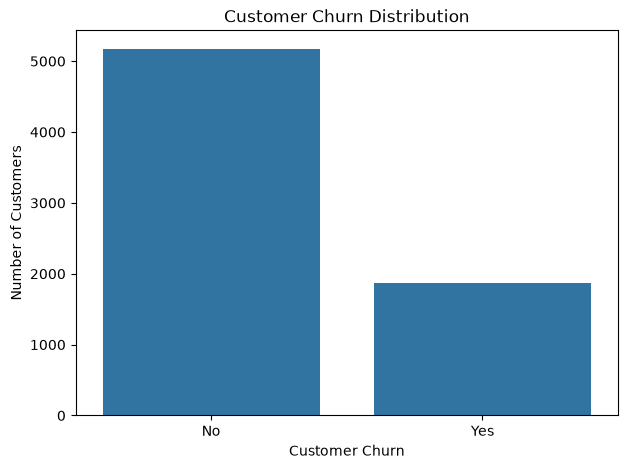

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [10]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print(df["Churn"].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


## 3. Feature and Target Separation

The Churn column is selected as the target variable.
All remaining customer attributes are used as input features.

In [11]:
# Separate input features
X = df.drop(columns=["Churn"])

# Target variable
y = df["Churn"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 19)
Target Shape: (7043,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (5634, 19)
Testing Data: (1409, 19)

Training Target Distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [13]:
# Identify numerical features
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [15]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

In [16]:
preprocessor = ColumnTransformer(
    transformers=[("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)])

In [17]:
class_weight="balanced"

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative Samples:", negative_count)
print("Positive Samples:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Negative Samples: 4139
Positive Samples: 1495
Scale Pos Weight: 2.768561872909699


In [ ]:
#Random Forest
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
#XGBoost
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [21]:
#Evaluating Random Forest Model using Cross-Validation
rf_cv_scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Random Forest CV Scores:", rf_cv_scores)
print("Random Forest Mean ROC-AUC:",
      rf_cv_scores.mean())

Random Forest CV Scores: [0.81601918 0.80827194 0.82867812 0.82005841 0.83984907]
Random Forest Mean ROC-AUC: 0.8225753436358192


In [22]:
#Evaluating XGBoost Model using Cross-Validation
xgb_cv_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("XGBoost CV Scores:", xgb_cv_scores)

print("XGBoost Mean ROC-AUC:",
      xgb_cv_scores.mean())

XGBoost CV Scores: [0.8394568  0.82804396 0.84352431 0.85840685 0.85386799]
XGBoost Mean ROC-AUC: 0.8446599829783862


In [ ]:
# Train Random Forest
rf_model.fit(X_train, y_train)
print("Random Forest training completed!")

Random Forest training completed!


In [24]:
# Train XGBoost
xgb_model.fit(X_train, y_train)
print("XGBoost training completed!")

XGBoost training completed!


In [25]:
# Class predictions
rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)

# Probability predictions for the positive class
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [26]:
from sklearn.model_selection import GridSearchCV

In [27]:
rf_params = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print("Best Random Forest ROC-AUC:")
print(rf_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Random Forest Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best Random Forest ROC-AUC:
0.8460000533973321


In [28]:
xgb_params = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.03, 0.05, 0.1]
}

xgb_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_params,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("Best XGBoost Parameters:")
print(xgb_search.best_params_)

print("Best XGBoost ROC-AUC:")
print(xgb_search.best_score_)

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best XGBoost Parameters:
{'classifier__learning_rate': 0.03, 'classifier__max_depth': 3, 'classifier__n_estimators': 200}
Best XGBoost ROC-AUC:
0.8484857839000816


In [29]:
# Select optimized models
best_rf_model = rf_search.best_estimator_
best_xgb_model = xgb_search.best_estimator_

# Generate class predictions
rf_predictions = best_rf_model.predict(X_test)
xgb_predictions = best_xgb_model.predict(X_test)

# Generate churn probabilities
rf_probabilities = best_rf_model.predict_proba(X_test)[:, 1]
xgb_probabilities = best_xgb_model.predict_proba(X_test)[:, 1]

print("Optimized predictions generated successfully!")

Optimized predictions generated successfully!


In [30]:
def evaluate_classifier(y_true, predictions, probabilities):

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1-Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

# Evaluate Random Forest
rf_results = evaluate_classifier(
    y_test,
    rf_predictions,
    rf_probabilities
)

# Evaluate XGBoost
xgb_results = evaluate_classifier(
    y_test,
    xgb_predictions,
    xgb_probabilities
)

# Create comparison table
comparison = pd.DataFrame(
    [rf_results, xgb_results],
    index=["Random Forest", "XGBoost"]
)
comparison

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest,0.751597,0.522388,0.748663,0.615385,0.838912
XGBoost,0.748758,0.517123,0.807487,0.630480,0.846297


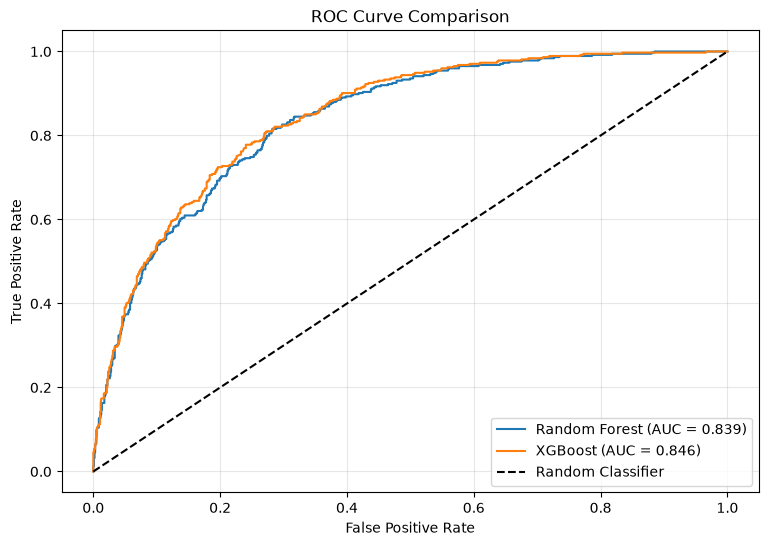

In [31]:
# Calculate ROC curve for Random Forest
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_probabilities
)

# Calculate ROC curve for XGBoost
xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_probabilities
)

# Calculate ROC-AUC
rf_auc = roc_auc_score(y_test, rf_probabilities)

xgb_auc = roc_auc_score(y_test, xgb_probabilities)


# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [32]:
print("Random Forest ROC-AUC:", round(rf_auc, 4))
print("XGBoost ROC-AUC:", round(xgb_auc, 4))

if rf_auc > 0.80:
    print("Random Forest achieved the target!")

if xgb_auc > 0.80:
    print("XGBoost achieved the target!")

if rf_auc <= 0.80 and xgb_auc <= 0.80:
    print("Neither model reached the target. Further tuning may help.")

Random Forest ROC-AUC: 0.8389
XGBoost ROC-AUC: 0.8463
Random Forest achieved the target!
XGBoost achieved the target!


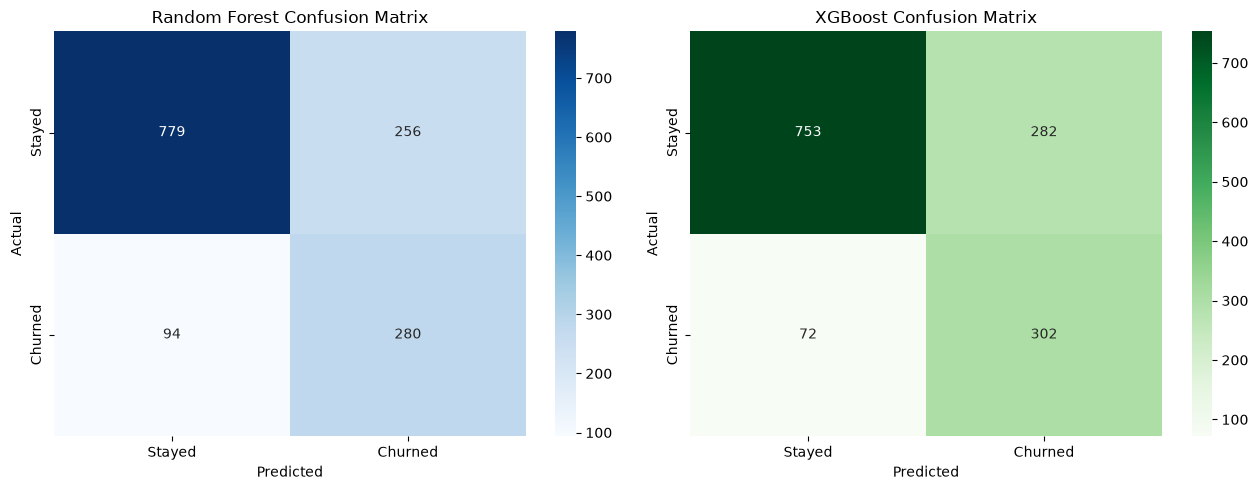

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Random Forest
rf_cm = confusion_matrix(y_test,rf_predictions)
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"],
    ax=axes[0]
)

axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
# XGBoost
xgb_cm = confusion_matrix(y_test,xgb_predictions)

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"],
    ax=axes[1]
)

axes[1].set_title("XGBoost Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [34]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=["Stayed", "Churned"]
    )
)

print("\nXGBOOST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        xgb_predictions,
        target_names=["Stayed", "Churned"]
    )
)

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.89      0.75      0.82      1035
     Churned       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.75      0.76      1409


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Stayed       0.91      0.73      0.81      1035
     Churned       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



In [35]:
# Get transformed feature names
feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract Random Forest feature importance
rf_importance = best_rf_model.named_steps[
    "classifier"
].feature_importances_

# Create DataFrame
rf_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

# Sort by importance
rf_feature_importance = rf_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_feature_importance.head(10)

,Feature,Importance
1,num__tenure,0.124081
36,cat__Contract_Month-to-month,0.117051
3,num__TotalCharges,0.103661
2,num__MonthlyCharges,0.075014
38,cat__Contract_Two year,0.061494
18,cat__OnlineSecurity_No,0.059098
27,cat__TechSupport_No,0.051461
16,cat__InternetService_Fiber optic,0.047967
43,cat__PaymentMethod_Electronic check,0.037924
37,cat__Contract_One year,0.019644


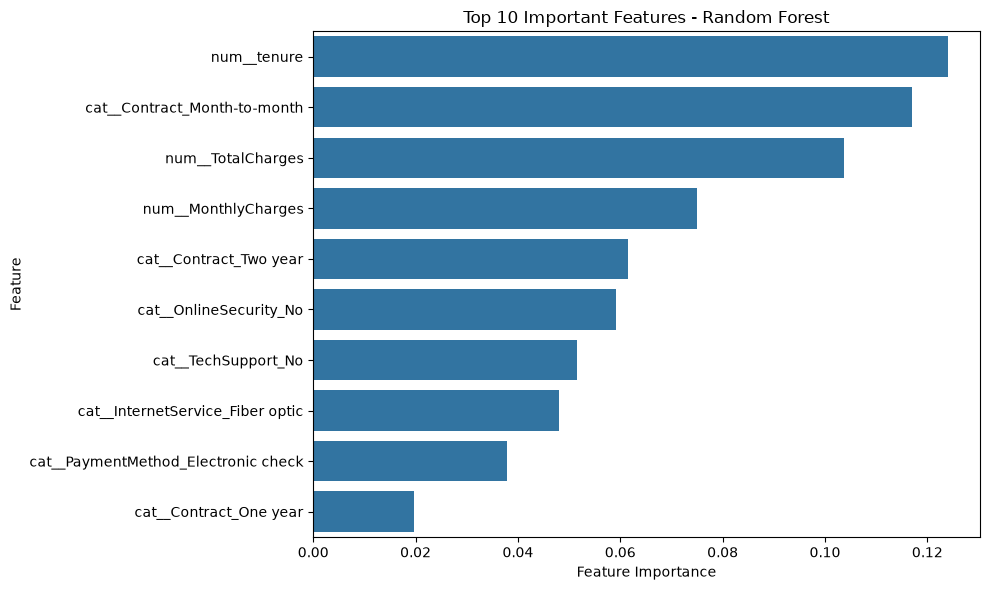

In [36]:
top_10_rf = rf_feature_importance.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(data=top_10_rf,x="Importance",y="Feature")

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [37]:
# Extract XGBoost feature importance
xgb_importance = best_xgb_model.named_steps[
    "classifier"
].feature_importances_

# Create DataFrame
xgb_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importance
})

# Sort by importance
xgb_feature_importance = xgb_feature_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_feature_importance.head(10)

,Feature,Importance
36,cat__Contract_Month-to-month,0.501148
27,cat__TechSupport_No,0.067762
16,cat__InternetService_Fiber optic,0.066922
18,cat__OnlineSecurity_No,0.065084
43,cat__PaymentMethod_Electronic check,0.033620
38,cat__Contract_Two year,0.029899
35,cat__StreamingMovies_Yes,0.027686
37,cat__Contract_One year,0.023055
1,num__tenure,0.022446
17,cat__InternetService_No,0.019781


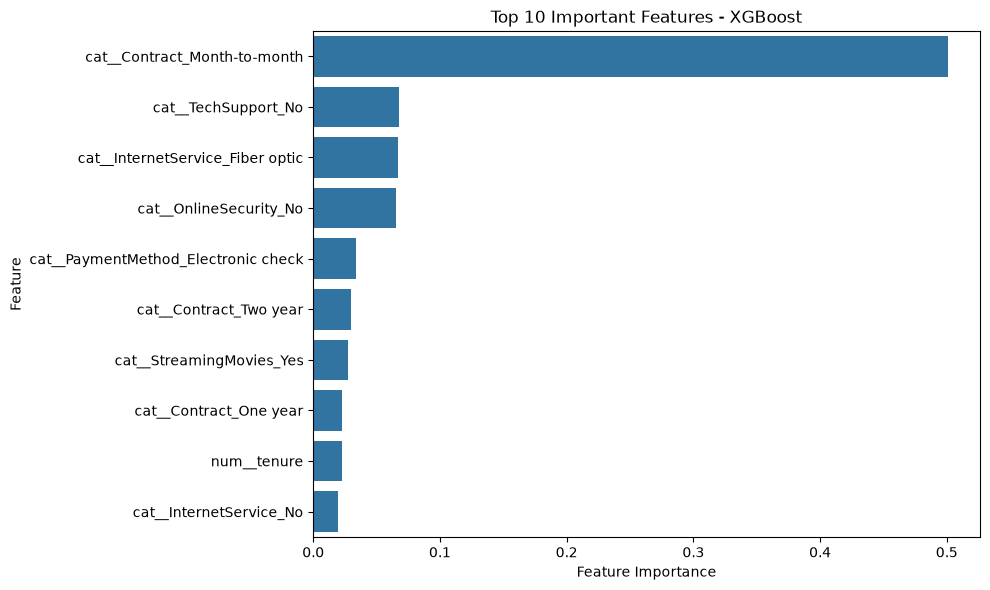

In [38]:
top_10_xgb = xgb_feature_importance.head(10)
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_xgb,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

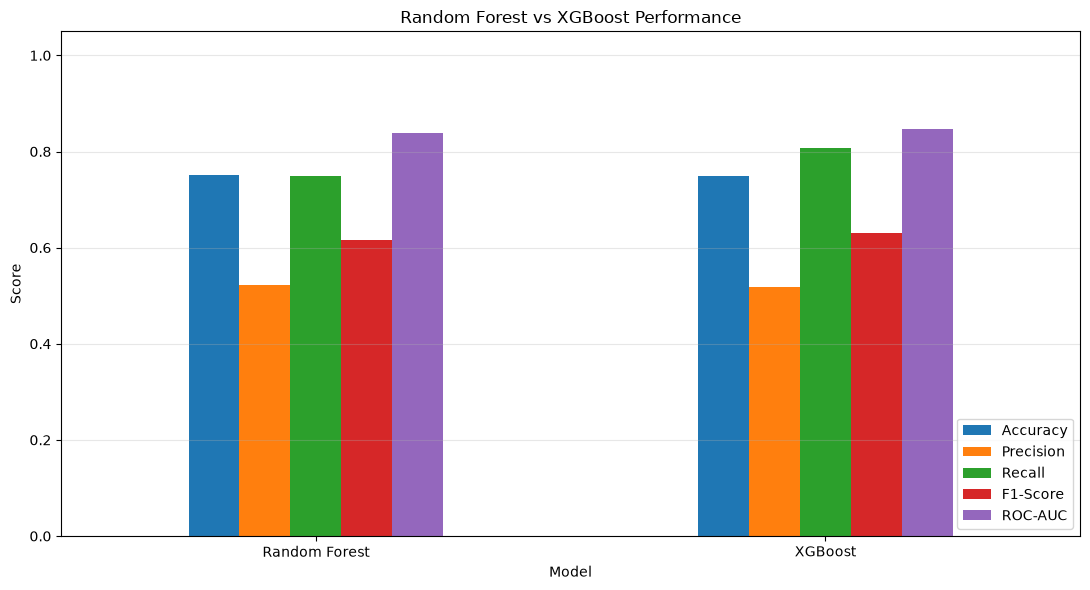

In [39]:
comparison.plot(kind="bar",figsize=(11, 6),ylim=(0, 1.05))

plt.title("Random Forest vs XGBoost Performance")
plt.ylabel("Score")
plt.xlabel("Model")

plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
best_model_name = (
    "Random Forest"
    if rf_auc > xgb_auc
    else "XGBoost"
)

best_auc = max(rf_auc, xgb_auc)

print("Best Model:", best_model_name)
print("Best ROC-AUC:", round(best_auc, 4))

Best Model: XGBoost
Best ROC-AUC: 0.8463


## 5. Conclusion

In this project, customer churn prediction was implemented using the Telco Customer Churn dataset.

Data preprocessing included handling missing values, converting TotalCharges into numerical format, and encoding categorical variables using OneHotEncoder.

Class imbalance was addressed using class weighting to give greater importance to minority-class customers.

Two ensemble learning algorithms, Random Forest and XGBoost, were trained and optimized using cross-validation
and GridSearchCV.

The models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

ROC curves and confusion matrices were generated to compare classification performance.

Feature importance analysis was also performed to identify the customer attributes that contributed most to churn
predictions.

Based on the evaluation results, the model, XGBoost with the
higher ROC-AUC score, 0.8463 was identified as the better performing classifier.

This project demonstrates an end-to-end customer churn prediction workflow using Python and Scikit-Learn.